## Step 3 - Class imbalance remedies

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, precision_recall_curve
)
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [2]:
from features import BankFeatureEngineer, make_preprocessor, build_full_pipeline, load_data

os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)

X_dev, y_dev, X_test, y_test = load_data()
print("Dev set:", X_dev.shape, "- positive rate:", round(y_dev.mean(), 4))

Dev set: (36168, 15) - positive rate: 0.117


In [3]:
# accuracy of a model that always says "no"
print("Accuracy if we always predict 0:", round(1 - y_dev.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def get_scores(model_name, remedy, y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "model": model_name,
        "remedy": remedy,
        "threshold": round(threshold, 3),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

Accuracy if we always predict 0: 0.883


In [4]:
def best_f1_threshold(y_true, y_proba):
    # threshold that gives the best F1 on the precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-10)
    best = np.argmax(f1[:-1])
    return thresholds[best]

In [5]:
models = {
    "Logistic Regression": [LogisticRegression(max_iter=1000), LogisticRegression(max_iter=1000, class_weight="balanced")],
    "LightGBM": [LGBMClassifier(random_state=42, verbose=-1), LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1)],
}

In [6]:
results = []
all_probas = {}

for name in models:
    print("\n----", name, "----")
    model_plain = models[name][0]
    model_weighted = models[name][1]

    # 1. baseline, no remedy
    pipe = build_full_pipeline(model_plain)
    proba_base = cross_val_predict(pipe, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    results.append(get_scores(name, "1. none", y_dev, proba_base))

    # 2. same model, we only move the threshold
    t = best_f1_threshold(y_dev, proba_base)
    results.append(get_scores(name, "2. threshold tuning", y_dev, proba_base, threshold=t))

    # 3. class weights
    pipe = build_full_pipeline(model_weighted)
    proba_weighted = cross_val_predict(pipe, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    results.append(get_scores(name, "3. class_weight", y_dev, proba_weighted))

    # 4. SMOTE -> needs the imblearn Pipeline so it is only done on the training folds
    pipe = ImbPipeline([
        ("engineering", BankFeatureEngineer()),
        ("preprocessing", make_preprocessor()),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model_plain)
    ])
    proba_smote = cross_val_predict(pipe, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    results.append(get_scores(name, "4. SMOTE", y_dev, proba_smote))

    all_probas[name] = {"none": proba_base, "class_weight": proba_weighted, "SMOTE": proba_smote}
    print("done")


---- Logistic Regression ----


done

---- LightGBM ----


done


In [7]:
results_df = pd.DataFrame(results)
print("\n--- RESULTS (5-fold CV, out-of-fold predictions) ---")
print(results_df.round(4).to_string(index=False))
results_df.to_csv("results/imbalance_comparison.csv", index=False)


--- RESULTS (5-fold CV, out-of-fold predictions) ---
              model              remedy  threshold  roc_auc  pr_auc  precision  recall     f1
Logistic Regression             1. none      0.500   0.7633  0.4013     0.6432  0.1751 0.2753
Logistic Regression 2. threshold tuning      0.191   0.7633  0.4013     0.4361  0.4507 0.4433
Logistic Regression     3. class_weight      0.500   0.7640  0.3978     0.2653  0.6218 0.3720
Logistic Regression            4. SMOTE      0.500   0.7586  0.3953     0.2586  0.6166 0.3644
           LightGBM             1. none      0.500   0.7969  0.4442     0.6168  0.2458 0.3515
           LightGBM 2. threshold tuning      0.228   0.7969  0.4442     0.4689  0.5039 0.4858
           LightGBM     3. class_weight      0.500   0.7948  0.4422     0.3545  0.6129 0.4492
           LightGBM            4. SMOTE      0.500   0.7858  0.4314     0.5648  0.3224 0.4105


In [8]:
# mean predicted probability vs real positive rate
# (class_weight and SMOTE push the probabilities up -> we will check this again in the calibration step)
print("\nReal positive rate:", round(y_dev.mean(), 4))
for name in all_probas:
    for remedy in all_probas[name]:
        print(name, "-", remedy, ": mean predicted proba =", round(all_probas[name][remedy].mean(), 4))


Real positive rate: 0.117
Logistic Regression - none : mean predicted proba = 0.117
Logistic Regression - class_weight : mean predicted proba = 0.4147
Logistic Regression - SMOTE : mean predicted proba = 0.4066
LightGBM - none : mean predicted proba = 0.1159
LightGBM - class_weight : mean predicted proba = 0.3589
LightGBM - SMOTE : mean predicted proba = 0.1576


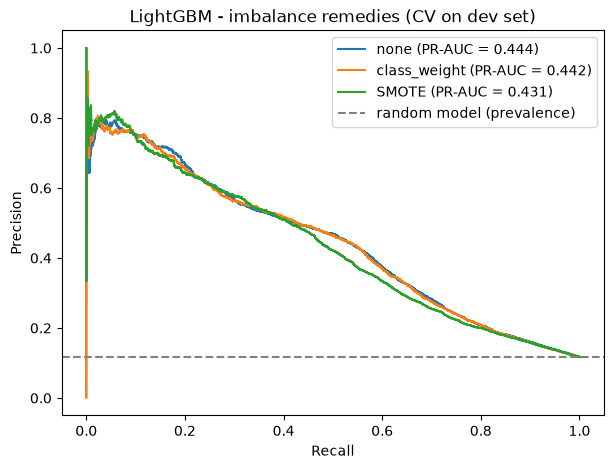


Saved plots/imbalance_pr_curves.png and results/imbalance_comparison.csv


In [9]:
# PR curves for LightGBM
plt.figure(figsize=(7, 5))
for remedy in all_probas["LightGBM"]:
    precision, recall, _ = precision_recall_curve(y_dev, all_probas["LightGBM"][remedy])
    ap = average_precision_score(y_dev, all_probas["LightGBM"][remedy])
    plt.plot(recall, precision, label=remedy + " (PR-AUC = " + str(round(ap, 3)) + ")")
plt.axhline(y_dev.mean(), color="grey", linestyle="--", label="random model (prevalence)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("LightGBM - imbalance remedies (CV on dev set)")
plt.legend()
plt.savefig("plots/imbalance_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved plots/imbalance_pr_curves.png and results/imbalance_comparison.csv")